# Day 32: Possession and territory control analysis in football

**Phase 2: EDA & Feature Engineering**

## Objective
Possession and territory control analysis in football

## Task
Calculate effective possession metrics, field tilt, final third passes. Create territory control visualizations. Compare team styles.

**Deliverable:** Notebook day032_possession_analysis.ipynb with control metrics.

---

### Instructions:
*Treat this as your course workbook. Write your code, notes, or execution steps below.*

Remember: 
- Document your decisions.
- Use clear variable names.
- If today's task involves creating a script in `src/`, a dashboard in `apps/`, or documentation in `docs/`, you can use this notebook to test your logic or simply write your reflections and proofs of execution (e.g. running terminal commands with `!`).



## 1. Possession Structure & Sequence Audit

**Objective:** Load the World Cup 2022 StatsBomb event stream (`sb_events_43_106.parquet`), inspect how possessions and timestamps are structured, and define clean filtering rules for effective possessions and completed passes across pitch thirds.

**Tactical Rationale:** Raw possession percentage treats sterile back-line circulation identically to sustained pressure in the opponent's final third. Before computing *Effective Possession* and *Field Tilt*, we must audit possession boundaries, event durations, and pass-completion encoding (`pass_outcome is NaN`).

**Hypothesis:** Filtering out non-ball-in-play administrative events and zero-second contested blips will yield clean possession durations and open-play final-third pass counts that reflect true tactical control.

In [6]:
from pathlib import Path
import pandas as pd
import numpy as np

# Resolve repository root reliably
cwd = Path.cwd()
REPO_ROOT = cwd if (cwd / "data").exists() else cwd.parent.parent
EVENTS_PATH = REPO_ROOT / "data" / "raw" / "statsbomb" / "sb_events_43_106.parquet"

df_events = pd.read_parquet(EVENTS_PATH)
print(f"Events shape: {df_events.shape}")
print(f"Unique matches: {df_events['match_id'].nunique()}")

print("\n--- Top 15 Event Types ---")
print(df_events["type"].value_counts().head(15))

print("\n--- Play Patterns ---")
print(df_events["play_pattern"].value_counts())

# 1. Audit possession durations (excluding administrative events without location/play)
admin_types = {"Starting XI", "Half Start", "Half End", "Tactical Shift", "Injury Stoppage", "Player Off", "Player On", "Substitution"}
df_active = df_events[~df_events["type"].isin(admin_types)].copy()
df_active["ts_td"] = pd.to_timedelta(df_active["timestamp"])

poss_summary = (
    df_active.groupby(["match_id", "period", "possession", "possession_team"])
    .agg(
        t_start=("ts_td", "min"),
        t_end=("ts_td", "max"),
        n_events=("type", "size"),
    )
    .reset_index()
)
poss_summary["poss_duration_sec"] = (poss_summary["t_end"] - poss_summary["t_start"]).dt.total_seconds()
print("\n--- Possession Duration (sec) Summary ---")
print(poss_summary["poss_duration_sec"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))
print(f"Zero-second possessions: {(poss_summary['poss_duration_sec'] == 0).mean() * 100:.1f}%")

# 2. Audit Final Third (x > 80) pass volume: Total vs Open-Play vs Completed
passes = df_events[df_events["type"] == "Pass"].copy()
passes["x"] = passes["location"].str[0]
final_third_passes = passes[passes["x"] > 80]

print("\n--- Final Third (x > 80) Pass Audit ---")
print(f"All attempted passes (x > 80):       {len(final_third_passes):,}")
print(f"Open-play attempted (pass_type NaN): {final_third_passes['pass_type'].isna().sum():,}")
print(f"Completed (pass_outcome NaN):        {final_third_passes['pass_outcome'].isna().sum():,}")
print(f"Open-play & completed:               {(final_third_passes['pass_type'].isna() & final_third_passes['pass_outcome'].isna()).sum():,}")


Events shape: (234652, 114)
Unique matches: 64

--- Top 15 Event Types ---
type
Pass              68515
Ball Receipt*     63715
Carry             53764
Pressure          16553
Ball Recovery      5821
Duel               4389
Clearance          2684
Block              2386
Dribble            1793
Goal Keeper        1790
Foul Committed     1775
Miscontrol         1755
Foul Won           1693
Shot               1494
Dispossessed       1431
Name: count, dtype: int64

--- Play Patterns ---
play_pattern
Regular Play      95174
From Throw In     57638
From Free Kick    39080
From Goal Kick    19470
From Corner        8063
From Kick Off      6933
From Keeper        5583
From Counter       1722
Other               989
Name: count, dtype: int64

--- Possession Duration (sec) Summary ---
count    11472.00
mean        20.49
std         65.89
min          0.00
10%          1.49
25%          4.30
50%         12.05
75%         26.48
90%         45.89
max       3215.59
Name: poss_duration_sec, dtype: f

### Key Takeaways: Possession Structure & Sequence Audit

- **Possession durations are heavily right-skewed:** Across **11,472** sequences in 64 World Cup matches, the median possession lasts **12.05 seconds** (IQR: 4.30–26.48s), while **3.8%** are 0-second contested blips and extreme timestamp outliers (up to 3,215s) reflect stoppage/VAR gaps rather than continuous ball-in-play time.
- **Final-third attrition is real:** Out of **15,071** attempted passes in $x > 80$, **12,451** are open-play (`pass_type is NaN`) and **9,200** are open-play completed (**73.9%** completion)—confirming that compact low blocks turn final-third volume into contested crosses and through-balls.

## 2. Effective Possession & Field Tilt

**Objective:** Compute team-level **Effective Possession** (share of active ball-in-play time / completed passes) and **Field Tilt** (share of open-play final-third passes in $x > 80$) at the match-team level, then aggregate across the 2022 World Cup.

**Tactical & Mathematical Definition:**
$$\text{Effective Possession}_A = \frac{\text{On-Ball Duration}_A}{\text{On-Ball Duration}_A + \text{On-Ball Duration}_B} \times 100$$
$$\text{Field Tilt}_A = \frac{\text{Open-Play Passes}_{A,\, x > 80}}{\text{Open-Play Passes}_{A,\, x > 80} + \text{Open-Play Passes}_{B,\, x > 80}} \times 100$$
Summing `duration` across active on-ball events (`Pass`, `Carry`, `Dribble`) measures true ball-in-play control and avoids inflating possession with VAR/stoppage gaps.

**Hypothesis:** Teams can diverge sharply between *Effective Possession* and *Field Tilt*—possession-heavy teams that circulate in midfield will post lower Field Tilt than Possession, whereas vertical/pressing sides will post higher Field Tilt than Possession.

In [7]:
# 1. Effective Possession (active on-ball duration: Pass, Carry, Dribble)
on_ball_types = {"Pass", "Carry", "Dribble"}
on_ball = df_events[df_events["type"].isin(on_ball_types)].copy()
on_ball["duration"] = on_ball["duration"].fillna(0.0)

match_dur = (
    on_ball.groupby(["match_id", "team"])["duration"]
    .sum()
    .rename("on_ball_sec")
    .reset_index()
)
match_dur["match_total_sec"] = match_dur.groupby("match_id")["on_ball_sec"].transform("sum")
match_dur["effective_possession_pct"] = 100.0 * match_dur["on_ball_sec"] / match_dur["match_total_sec"]

# 2. Pass-share Possession (completed passes)
comp_passes = df_events[(df_events["type"] == "Pass") & (df_events["pass_outcome"].isna())]
match_pass_share = (
    comp_passes.groupby(["match_id", "team"])
    .size()
    .rename("completed_passes")
    .reset_index()
)
match_pass_share["match_total_comp"] = match_pass_share.groupby("match_id")["completed_passes"].transform("sum")
match_pass_share["pass_possession_pct"] = 100.0 * match_pass_share["completed_passes"] / match_pass_share["match_total_comp"]

# 3. Field Tilt (open-play attempted passes in final third x > 80)
open_ft_passes = df_events[
    (df_events["type"] == "Pass") &
    (df_events["pass_type"].isna()) &
    (df_events["location"].str[0] > 80)
]
match_ft = (
    open_ft_passes.groupby(["match_id", "team"])
    .size()
    .rename("ft_passes")
    .reset_index()
)
# Left join onto match_dur so teams with 0 final-third passes in a match get 0 rather than NaN
match_control = (
    match_dur.merge(match_pass_share[["match_id", "team", "completed_passes", "pass_possession_pct"]], on=["match_id", "team"], how="left")
    .merge(match_ft, on=["match_id", "team"], how="left")
    .fillna({"ft_passes": 0, "completed_passes": 0})
)
match_control["match_total_ft"] = match_control.groupby("match_id")["ft_passes"].transform("sum")
match_control["field_tilt_pct"] = np.where(
    match_control["match_total_ft"] > 0,
    100.0 * match_control["ft_passes"] / match_control["match_total_ft"],
    50.0,
)

# 4. Aggregate per National Team across tournament matches
team_control = (
    match_control.groupby("team")
    .agg(
        matches=("match_id", "nunique"),
        eff_poss_pct=("effective_possession_pct", "mean"),
        pass_poss_pct=("pass_possession_pct", "mean"),
        field_tilt_pct=("field_tilt_pct", "mean"),
        ft_passes_pg=("ft_passes", "mean"),
    )
    .reset_index()
)
team_control["tilt_minus_poss"] = team_control["field_tilt_pct"] - team_control["eff_poss_pct"]

print("--- Top 10 Teams by Field Tilt (%) ---")
print(team_control.sort_values("field_tilt_pct", ascending=False).head(10).round(2).to_string(index=False))

print("\n--- Biggest Negative Gap (Sterile Possession: Poss >> Tilt) ---")
print(team_control.sort_values("tilt_minus_poss", ascending=True).head(6).round(2).to_string(index=False))

print("\n--- Biggest Positive Gap (Direct Territorial Pressure: Tilt > Poss) ---")
print(team_control.sort_values("tilt_minus_poss", ascending=False).head(6).round(2).to_string(index=False))


--- Top 10 Teams by Field Tilt (%) ---
         team  matches  eff_poss_pct  pass_poss_pct  field_tilt_pct  ft_passes_pg  tilt_minus_poss
        Spain        4         74.91          79.04           80.63        193.25             5.71
      Germany        3         59.10          60.26           69.74        167.00            10.65
     Portugal        5         60.52          62.66           68.08        124.00             7.57
      Denmark        3         58.25          62.35           65.84        120.00             7.58
      England        5         63.21          65.40           65.48        112.40             2.27
    Argentina        7         57.98          59.45           64.35        129.57             6.37
       Brazil        5         56.04          57.29           63.99        145.60             7.95
United States        4         54.04          53.76           61.56        119.50             7.53
       Canada        3         53.41          53.12           60.15   

### Key Takeaways: Effective Possession vs. Field Tilt

- **Territorial control $\neq$ raw possession:** **Senegal** averaged only **45.21%** Effective Possession yet generated **55.77%** Field Tilt (`+10.56` pp), demonstrating aggressive verticality and pressing. Conversely, **Belgium** held **55.38%** of the ball but posted just **44.52%** Field Tilt (`-10.87` pp)—textbook sterile possession.
- **Total dominance at the top:** **Spain** led the tournament in both Effective Possession (**74.91%**) and Field Tilt (**80.63%**, 193.3 final-third passes/match), while **Germany** (`+10.65` pp) and **Brazil** (`+7.95` pp) paired solid possession with relentless final-third territory.

## 3. Final Third Execution & Dangerous Zone Entries

**Objective:** Quantify line-breaking progression and execution quality in the attacking third via **Final Third Entries**, **Penalty Box Entries**, and **Final Third Pass Completion (%)**.

**Tactical & Mathematical Definitions (StatsBomb $120 \times 80$ Pitch):**
- **Final Third Entry:** Completed open-play pass originating outside the final third and ending inside:
  $$x_{\text{start}} \le 80 \quad \land \quad x_{\text{end}} > 80$$
- **Penalty Box Entry:** Completed open-play pass originating outside the 18-yard box and ending inside:
  $$\neg(x_{\text{start}} \ge 102 \land 18 \le y_{\text{start}} \le 62) \quad \land \quad (x_{\text{end}} \ge 102 \land 18 \le y_{\text{end}} \le 62)$$
Requiring the origin to be *outside* the target zone ensures we measure true zone penetration rather than short lateral circulation already inside the box.

**Hypothesis:** High-possession teams with strong box-entry rates (e.g., Argentina, Brazil, France) convert territorial control into real penalty-area danger, whereas sterile-possession sides generate final-third volume without penetrating the box.

In [8]:
# 1. Prepare open-play passes with start and end coordinates
open_passes = df_events[
    (df_events["type"] == "Pass") & (df_events["pass_type"].isna())
].copy()
open_passes["x_start"] = open_passes["location"].str[0]
open_passes["y_start"] = open_passes["location"].str[1]
open_passes["x_end"] = open_passes["pass_end_location"].str[0]
open_passes["y_end"] = open_passes["pass_end_location"].str[1]
open_passes["is_completed"] = open_passes["pass_outcome"].isna()

# Zone flags
in_box_start = (open_passes["x_start"] >= 102) & (open_passes["y_start"].between(18, 62))
in_box_end = (open_passes["x_end"] >= 102) & (open_passes["y_end"].between(18, 62))

open_passes["is_ft_pass"] = open_passes["x_start"] > 80
open_passes["is_ft_comp"] = open_passes["is_ft_pass"] & open_passes["is_completed"]
open_passes["is_ft_entry"] = (open_passes["x_start"] <= 80) & (open_passes["x_end"] > 80) & open_passes["is_completed"]
open_passes["is_box_entry"] = (~in_box_start) & in_box_end & open_passes["is_completed"]

# 2. Aggregate per match-team and average per team
match_entries = (
    open_passes.groupby(["match_id", "team"])
    .agg(
        ft_att=("is_ft_pass", "sum"),
        ft_comp=("is_ft_comp", "sum"),
        ft_entries=("is_ft_entry", "sum"),
        box_entries=("is_box_entry", "sum"),
    )
    .reset_index()
)
match_entries["ft_comp_pct"] = np.where(
    match_entries["ft_att"] > 0,
    100.0 * match_entries["ft_comp"] / match_entries["ft_att"],
    0.0,
)

team_entries = (
    match_entries.groupby("team")
    .agg(
        ft_comp_pg=("ft_comp", "mean"),
        ft_comp_pct=("ft_comp_pct", "mean"),
        ft_entries_pg=("ft_entries", "mean"),
        box_entries_pg=("box_entries", "mean"),
    )
    .reset_index()
)

team_control = team_control.merge(team_entries, on="team", how="left")

print("--- Top 10 Teams by Penalty Box Entries per Match ---")
print(
    team_control[["team", "matches", "field_tilt_pct", "ft_entries_pg", "box_entries_pg", "ft_comp_pct"]]
    .sort_values("box_entries_pg", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)


--- Top 10 Teams by Penalty Box Entries per Match ---
       team  matches  field_tilt_pct  ft_entries_pg  box_entries_pg  ft_comp_pct
    Germany        3           69.74          42.00           16.00        75.19
      Spain        4           80.63          64.75           11.75        80.98
   Portugal        5           68.08          35.40            9.80        75.83
     Brazil        5           63.99          39.40            9.80        78.38
  Argentina        7           64.35          33.29            8.86        77.46
    Denmark        3           65.84          42.00            8.67        72.08
     Canada        3           60.15          36.33            8.33        69.81
     France        7           52.73          35.71            8.29        77.83
South Korea        4           53.81          30.75            8.25        75.91
    Croatia        7           54.89          35.29            8.14        70.78


### Key Takeaways: Final Third Execution & Dangerous Zone Entries

- **Volume outside the box $\neq$ box penetration:** **Spain** generated **64.75** final-third entries/match at **80.98%** completion, yet **Germany** led the entire tournament in **Penalty Box Entries (16.00/match)** despite fewer final-third entries (**42.00/match**)—confirming Germany's relentless verticality versus Spain's perimeter circulation.
- **Tournament-winning efficiency:** **France** posted a modest **52.73%** Field Tilt, yet still delivered **8.29 Box Entries/match** at **77.83%** final-third accuracy—proving that direct transition attacks can match possession giants in penalty-area threat.

## 4. Territory Control Visualizations & Team Style Archetypes

### 4.1 Tactical Quadrant: Effective Possession vs. Field Tilt

**Objective:** Map all 32 World Cup 2022 national teams into four tactical archetypes using **Effective Possession (%)** vs. **Field Tilt (%)**, with bubble size encoding **Penalty Box Entries per Match**.

**Tactical Rationale:** Plotting Possession against Field Tilt around the `50%` equilibrium axes immediately separates *Dominant Control* (top-right) and *Vertical Pressure* (top-left) from *Sterile Possession* (bottom-right) and *Low-Block / Counter* (bottom-left).

**Hypothesis:** Teams in the top-left (*Vertical Pressure*, e.g., Senegal) and top-right (*Dominant Control*, e.g., Spain, Germany, Argentina) will display markedly larger box-entry bubbles than bottom-right (*Sterile Possession*, e.g., Belgium).

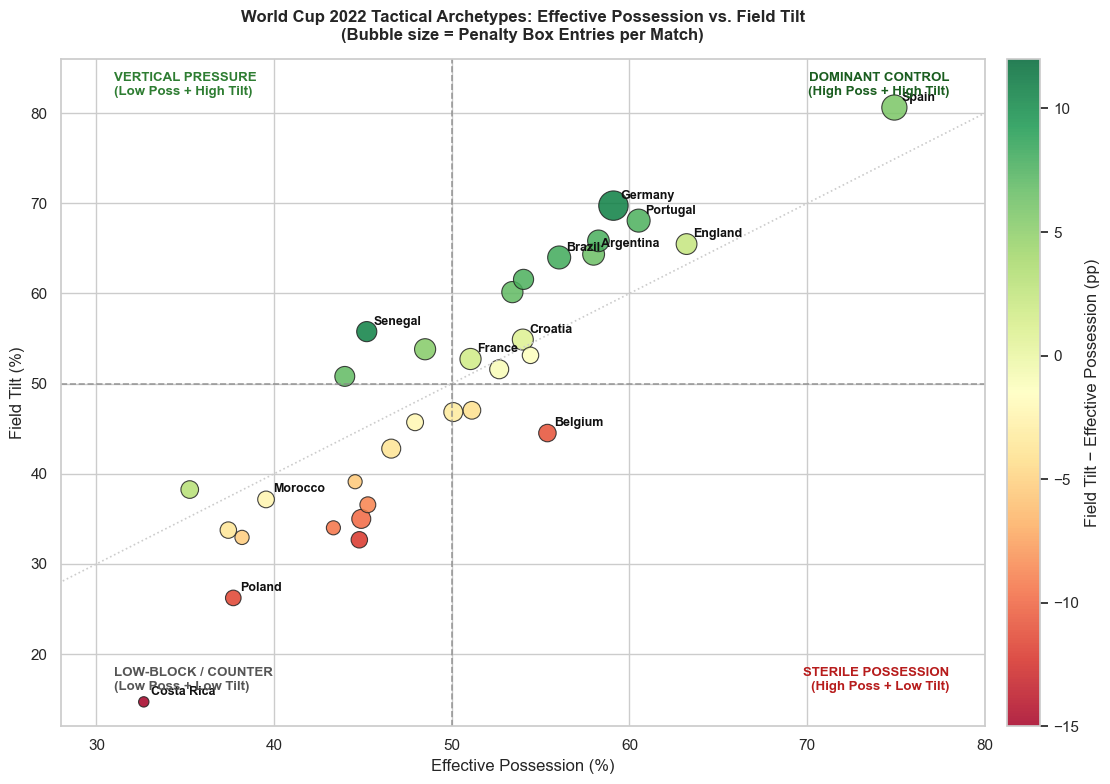

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 8))
ax.axvline(50, color="#888888", linestyle="--", linewidth=1.2, alpha=0.8)
ax.axhline(50, color="#888888", linestyle="--", linewidth=1.2, alpha=0.8)
ax.plot([25, 85], [25, 85], color="#cccccc", linestyle=":", linewidth=1.2, label="Parity (Tilt = Possession)")

scatter = ax.scatter(
    team_control["eff_poss_pct"],
    team_control["field_tilt_pct"],
    s=team_control["box_entries_pg"] * 28,
    c=team_control["tilt_minus_poss"],
    cmap="RdYlGn",
    vmin=-15,
    vmax=12,
    alpha=0.85,
    edgecolors="#222222",
    linewidth=0.8,
)

# Annotate key tactical archetypes
highlight_teams = {
    "Spain", "Germany", "Argentina", "Brazil", "France", "Portugal",
    "England", "Senegal", "Belgium", "Croatia", "Morocco", "Costa Rica", "Poland"
}
for _, row in team_control.iterrows():
    if row["team"] in highlight_teams:
        ax.annotate(
            row["team"],
            (row["eff_poss_pct"], row["field_tilt_pct"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color="#111111",
        )

# Quadrant labels
ax.text(78, 82, "DOMINANT CONTROL\n(High Poss + High Tilt)", fontsize=9.5, fontweight="bold", color="#1b5e20", ha="right")
ax.text(31, 82, "VERTICAL PRESSURE\n(Low Poss + High Tilt)", fontsize=9.5, fontweight="bold", color="#2e7d32", ha="left")
ax.text(78, 16, "STERILE POSSESSION\n(High Poss + Low Tilt)", fontsize=9.5, fontweight="bold", color="#b71c1c", ha="right")
ax.text(31, 16, "LOW-BLOCK / COUNTER\n(Low Poss + Low Tilt)", fontsize=9.5, fontweight="bold", color="#555555", ha="left")

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("Field Tilt − Effective Possession (pp)")
ax.set_xlim(28, 80)
ax.set_ylim(12, 86)
ax.set_title("World Cup 2022 Tactical Archetypes: Effective Possession vs. Field Tilt\n(Bubble size = Penalty Box Entries per Match)", fontweight="bold", pad=14)
ax.set_xlabel("Effective Possession (%)")
ax.set_ylabel("Field Tilt (%)")
plt.tight_layout()
plt.show()


### 4.2 Zonal Territory Control Heatmaps (`mplsoccer`) & 32-Team Animated GIF

**Objective:** Visualize spatial passing distribution across a $6 \times 4$ tactical grid using `mplsoccer`—comparing four contrasting styles (**Spain**, **Germany**, **France**, **Belgium**) side-by-side and generating a tournament-wide animated GIF across all 32 nations.

**Tactical Rationale:** Normalizing each zone's completed open-play passes by the team's total completed passes (`statistic` share %) eliminates match-count bias (7-match finalists vs. 3-match group exits) and highlights *where* on the pitch each team builds and penetrates.

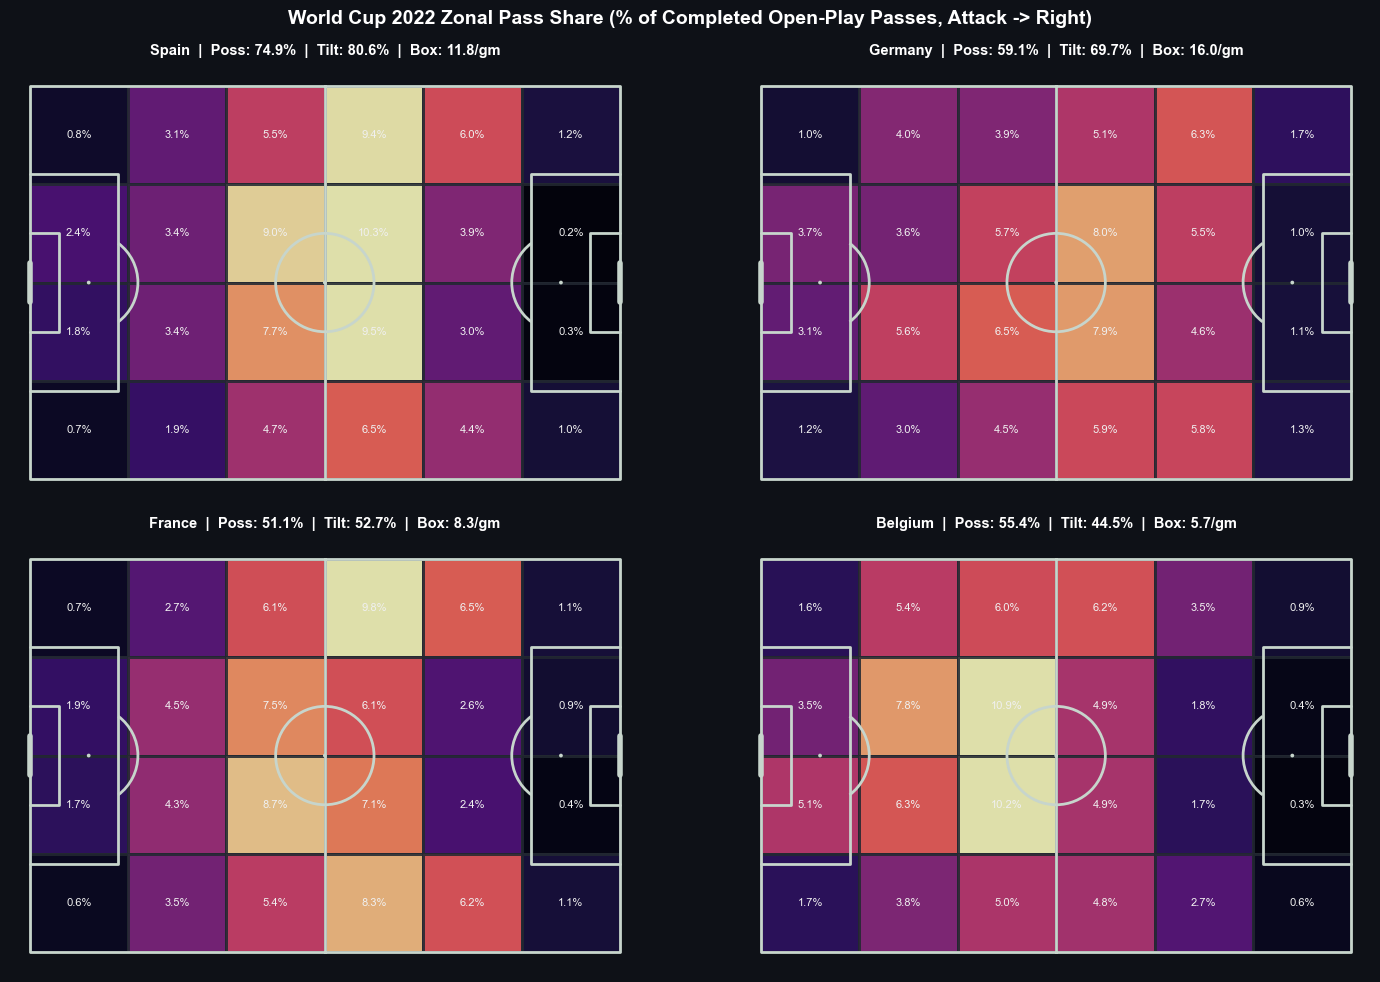

[SAVED] Animated 32-team territory GIF -> c:\Users\david\Desktop\David\Documentos\David\GitHub\100-days-Data-Sports-Challenge\reports\figures\wc2022_territory_control.gif


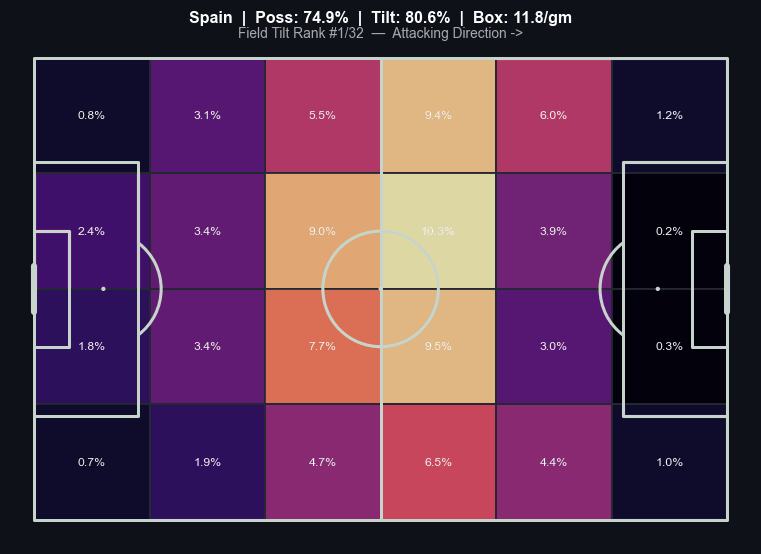

In [10]:
import io
from PIL import Image as PILImage
from IPython.display import Image as IPyImage, display
from mplsoccer import Pitch

comp_open = open_passes[open_passes["is_completed"]].copy()
pitch = Pitch(pitch_type="statsbomb", pitch_color="#0e1117", line_color="#c7d5cc", line_zorder=2)

def plot_team_zone_heatmap(ax: plt.Axes, team_name: str, vmax_pct: float = 10.0) -> None:
    """Render a normalized 6x4 zonal pass share heatmap for a given team."""
    sub = comp_open[comp_open["team"] == team_name]
    pitch.draw(ax=ax)
    bin_stat = pitch.bin_statistic(sub["x_start"], sub["y_start"], statistic="count", bins=(6, 4))
    total = bin_stat["statistic"].sum()
    if total > 0:
        bin_stat["statistic"] = 100.0 * bin_stat["statistic"] / total
    pitch.heatmap(bin_stat, ax=ax, cmap="magma", edgecolors="#222831", vmin=0, vmax=vmax_pct, alpha=0.88)
    pitch.label_heatmap(bin_stat, color="#f0f0f0", fontsize=8, ax=ax, ha="center", va="center", str_format="{:.1f}%")
    row = team_control[team_control["team"] == team_name].iloc[0]
    ax.set_title(
        f"{team_name}  |  Poss: {row['eff_poss_pct']:.1f}%  |  Tilt: {row['field_tilt_pct']:.1f}%  |  Box: {row['box_entries_pg']:.1f}/gm",
        color="white", fontsize=10.5, fontweight="bold", pad=8
    )

# 1. Static 2x2 Comparison of 4 Contrasting Tactical Styles
fig, axes = plt.subplots(2, 2, figsize=(15, 10), facecolor="#0e1117")
for ax, t in zip(axes.flat, ["Spain", "Germany", "France", "Belgium"]):
    plot_team_zone_heatmap(ax, t, vmax_pct=9.5)
fig.suptitle("World Cup 2022 Zonal Pass Share (% of Completed Open-Play Passes, Attack -> Right)", color="white", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

# 2. Bonus: Animated GIF cycling through all 32 teams sorted by Field Tilt
GIF_PATH = REPO_ROOT / "reports" / "figures" / "wc2022_territory_control.gif"
GIF_PATH.parent.mkdir(parents=True, exist_ok=True)

ordered_teams = team_control.sort_values("field_tilt_pct", ascending=False)["team"].tolist()
frames = []
for rank, t in enumerate(ordered_teams, start=1):
    fig_f, ax_f = plt.subplots(figsize=(9, 6), facecolor="#0e1117")
    plot_team_zone_heatmap(ax_f, t, vmax_pct=10.5)
    ax_f.text(60, -3.5, f"Field Tilt Rank #{rank}/32  —  Attacking Direction ->", color="#aaaaaa", ha="center", fontsize=9)
    buf = io.BytesIO()
    fig_f.savefig(buf, format="png", dpi=110, facecolor="#0e1117", bbox_inches="tight")
    plt.close(fig_f)
    buf.seek(0)
    frames.append(PILImage.open(buf).convert("P", palette=PILImage.ADAPTIVE))

frames[0].save(
    GIF_PATH,
    save_all=True,
    append_images=frames[1:],
    duration=1100,
    loop=0,
)
print(f"[SAVED] Animated 32-team territory GIF -> {GIF_PATH}")
display(IPyImage(filename=str(GIF_PATH)))


### Key Takeaways: Territory Control & Tactical Styles

- **Four distinct World Cup 2022 archetypes:** The Possession vs. Field Tilt quadrant cleanly separates **Dominant Control** (Spain, Germany, Portugal, Argentina, Brazil), **Vertical Pressure** (Senegal), **Sterile Possession** (Belgium), and **Low-Block / Counter** (Costa Rica, Poland, Morocco).
- **Spatial signatures in `mplsoccer`:** Zonal pass-share heatmaps reveal *how* teams tilt the pitch—**Spain** concentrates high pass shares in the middle/half-spaces ahead of the box, **Germany** pushes heavy volume directly into final-third channels, **France** operates balanced transition zones, and **Belgium** remains trapped in deeper midfield zones.